# Model performance

In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

BASE_DIR = Path('.')
PARITY_DIR = BASE_DIR / 'Figure_data' / 'parity_plot'
OUT_DIR = PARITY_DIR / 'summary'
OUT_DIR.mkdir(exist_ok=True)

SPLITS = ['train', 'valid', 'test']

MODELS = {
    'BLI_GCN':   'BLI_GCN',
    'BLI_ECFP':  'BLI_ECFP+descriptors',
    'BLI_GAT':   'BLI_GAT',
    'BLI_DMPNN': 'BLI_DMPNN',
    'CLI_GCN':   'CLI_GCN',
    'CLI_ECFP':  'CLI_ECFP+descriptors',
    'CLI_GAT':   'CLI_GAT',
    'CLI_DMPNN': 'CLI_DMPNN'
}

SPLIT_STYLE = {
    'train': dict(color='blue', marker='o'),
    'valid': dict(color='purple', marker='o'),
    'test':  dict(color='red', marker='o'),
}

In [28]:
# result
def find_split_file(model_dir, split):
    files = sorted(p for p in model_dir.glob('*.csv') if f'_{split}' in p.stem)
    if len(files) != 1:
        raise FileNotFoundError(f'{model_dir} err in file {split} couldnt be specified: {files}')
    return files[0]


def load_parity(model_dir, split):
    df = pd.read_csv(find_split_file(model_dir, split))
    df = df.rename(columns={f'{split}_label': 'label', f'{split}_pred': 'pred'})[['label', 'pred']]
    return df.dropna().reset_index(drop=True)


data = {
    (name, split): load_parity(PARITY_DIR / folder, split)
    for name, folder in MODELS.items()
    for split in SPLITS
}

# for name in MODELS:
#     print(f'{name:10s}', {split: len(data[(name, split)]) for split in SPLITS})

# calc
def calc_metrics(df):
    y, p = df['label'].values, df['pred'].values
    return {
        'R2':   r2_score(y, p),
        'MAE':  mean_absolute_error(y, p),
        'RMSE': np.sqrt(mean_squared_error(y, p)),
        'N':    len(df),
    }


metrics = pd.DataFrame(
    [{'model': name, 'split': split, **calc_metrics(data[(name, split)])}
     for name in MODELS for split in SPLITS]
)
metrics['N'] = metrics['N'].astype(int)
metrics.to_csv(OUT_DIR / 'metrics_all.csv', index=False)

# metrics.set_index(['model', 'split']).style.format({'R2': '{:.4f}', 'MAE': '{:.4f}', 'RMSE': '{:.4f}'})

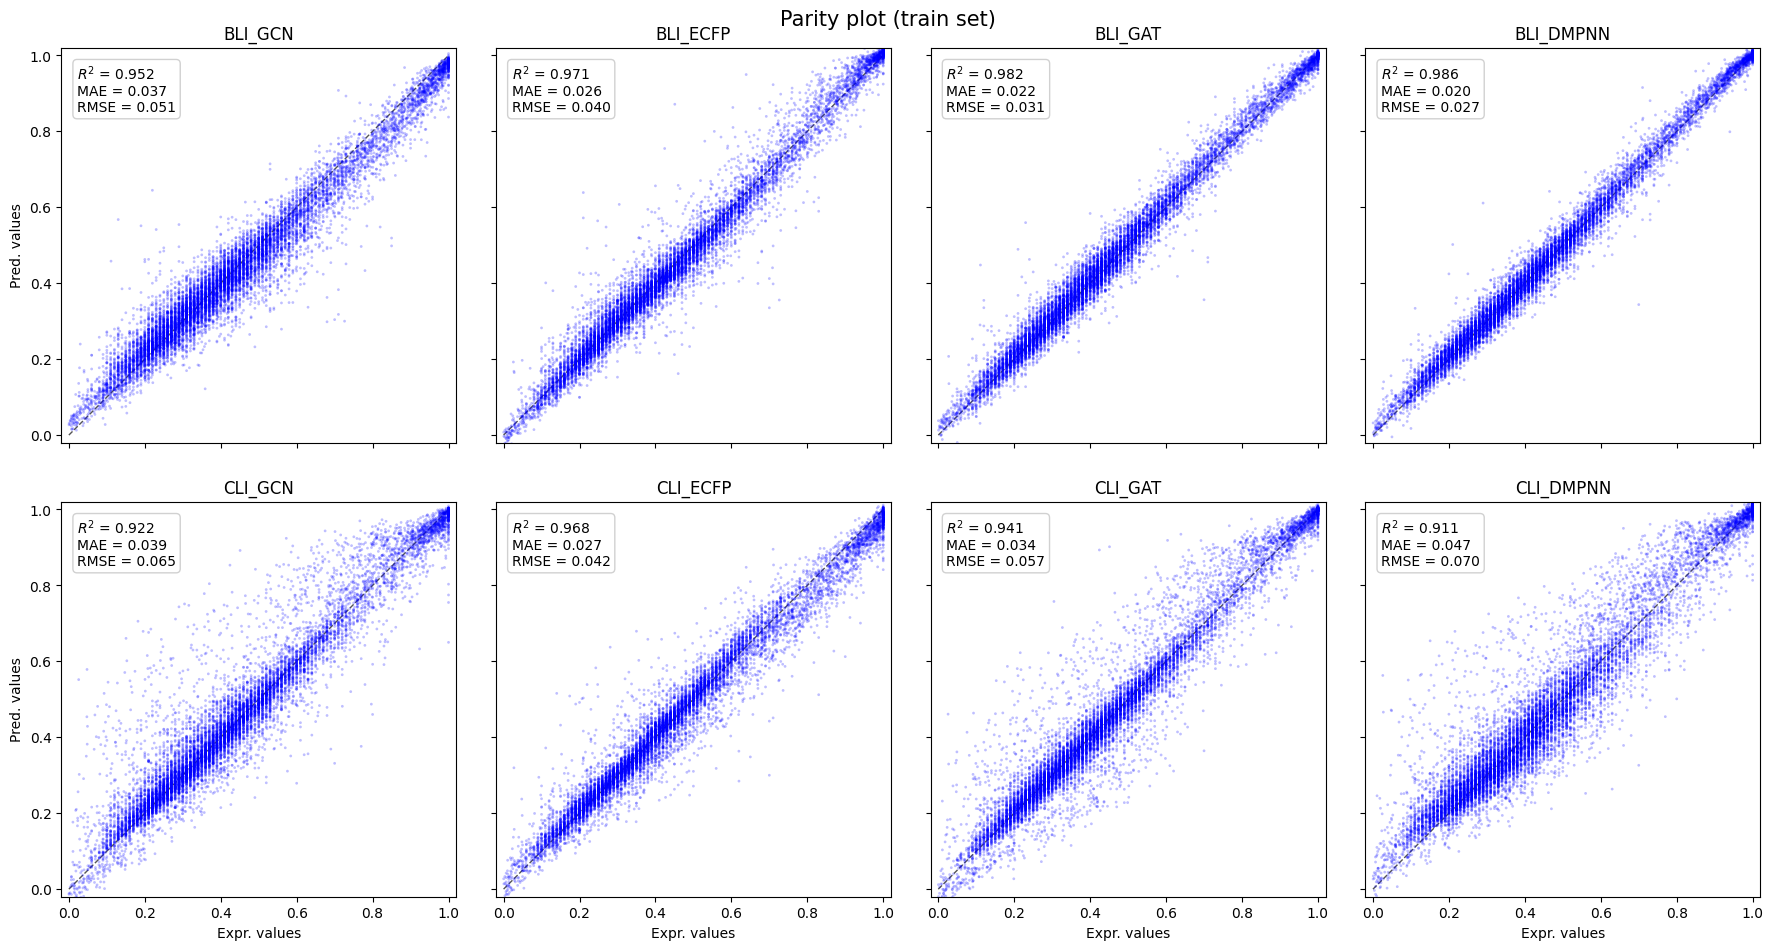

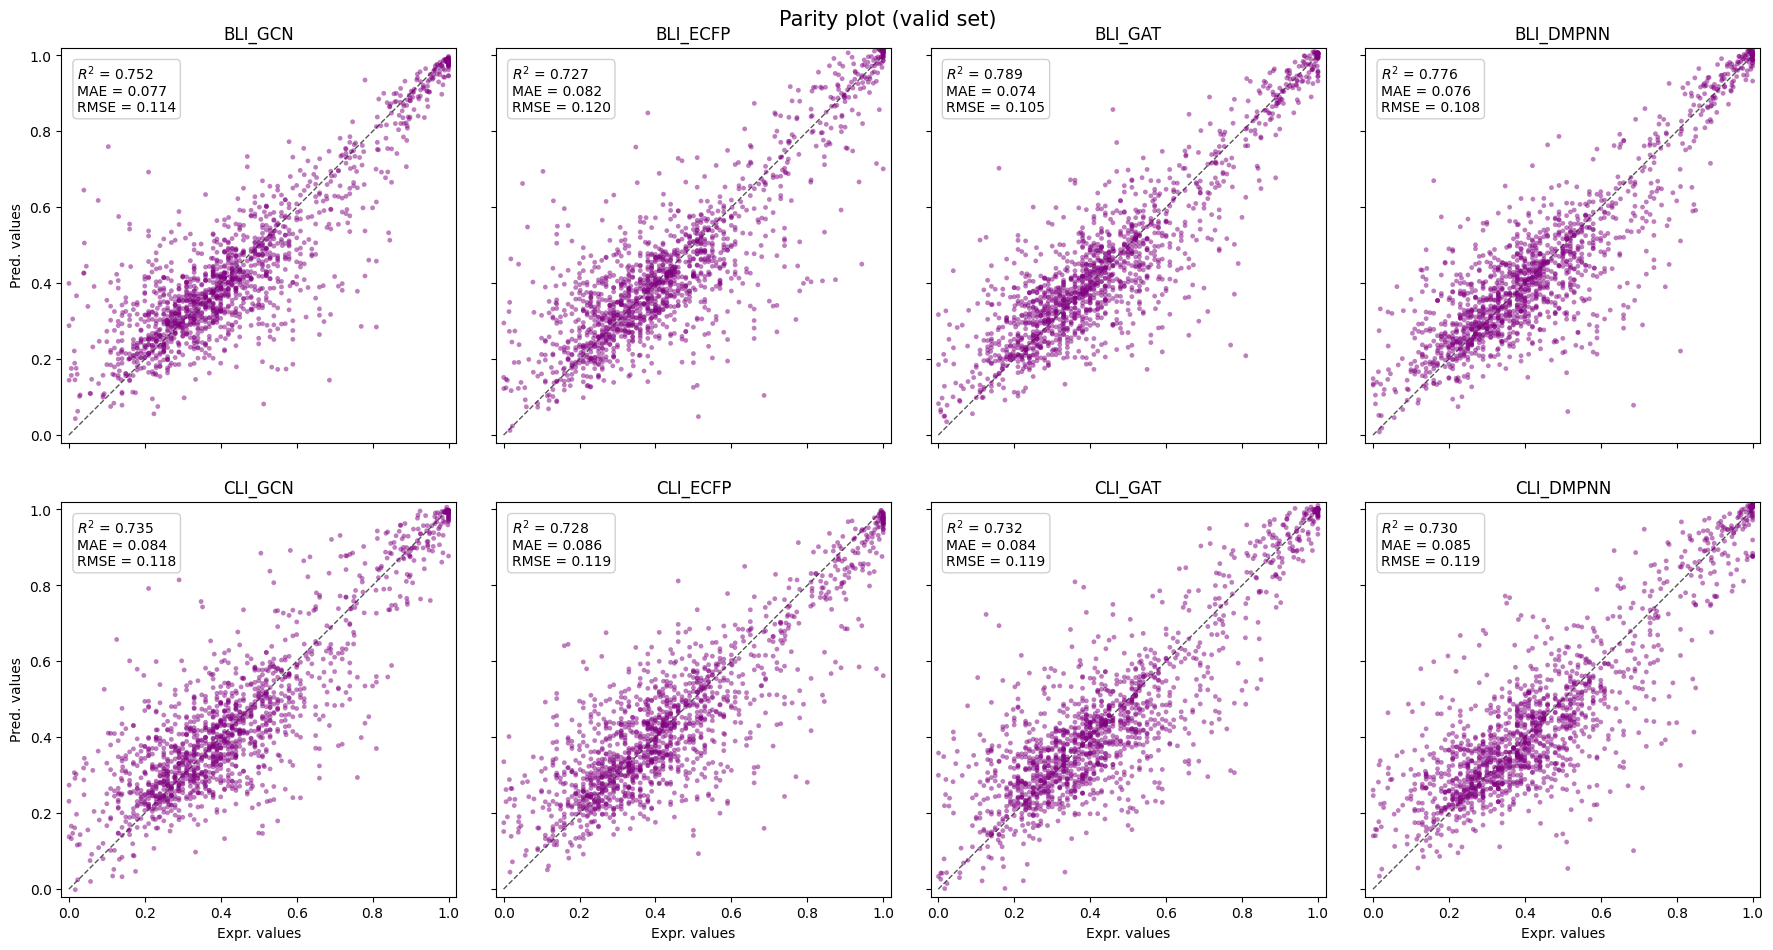

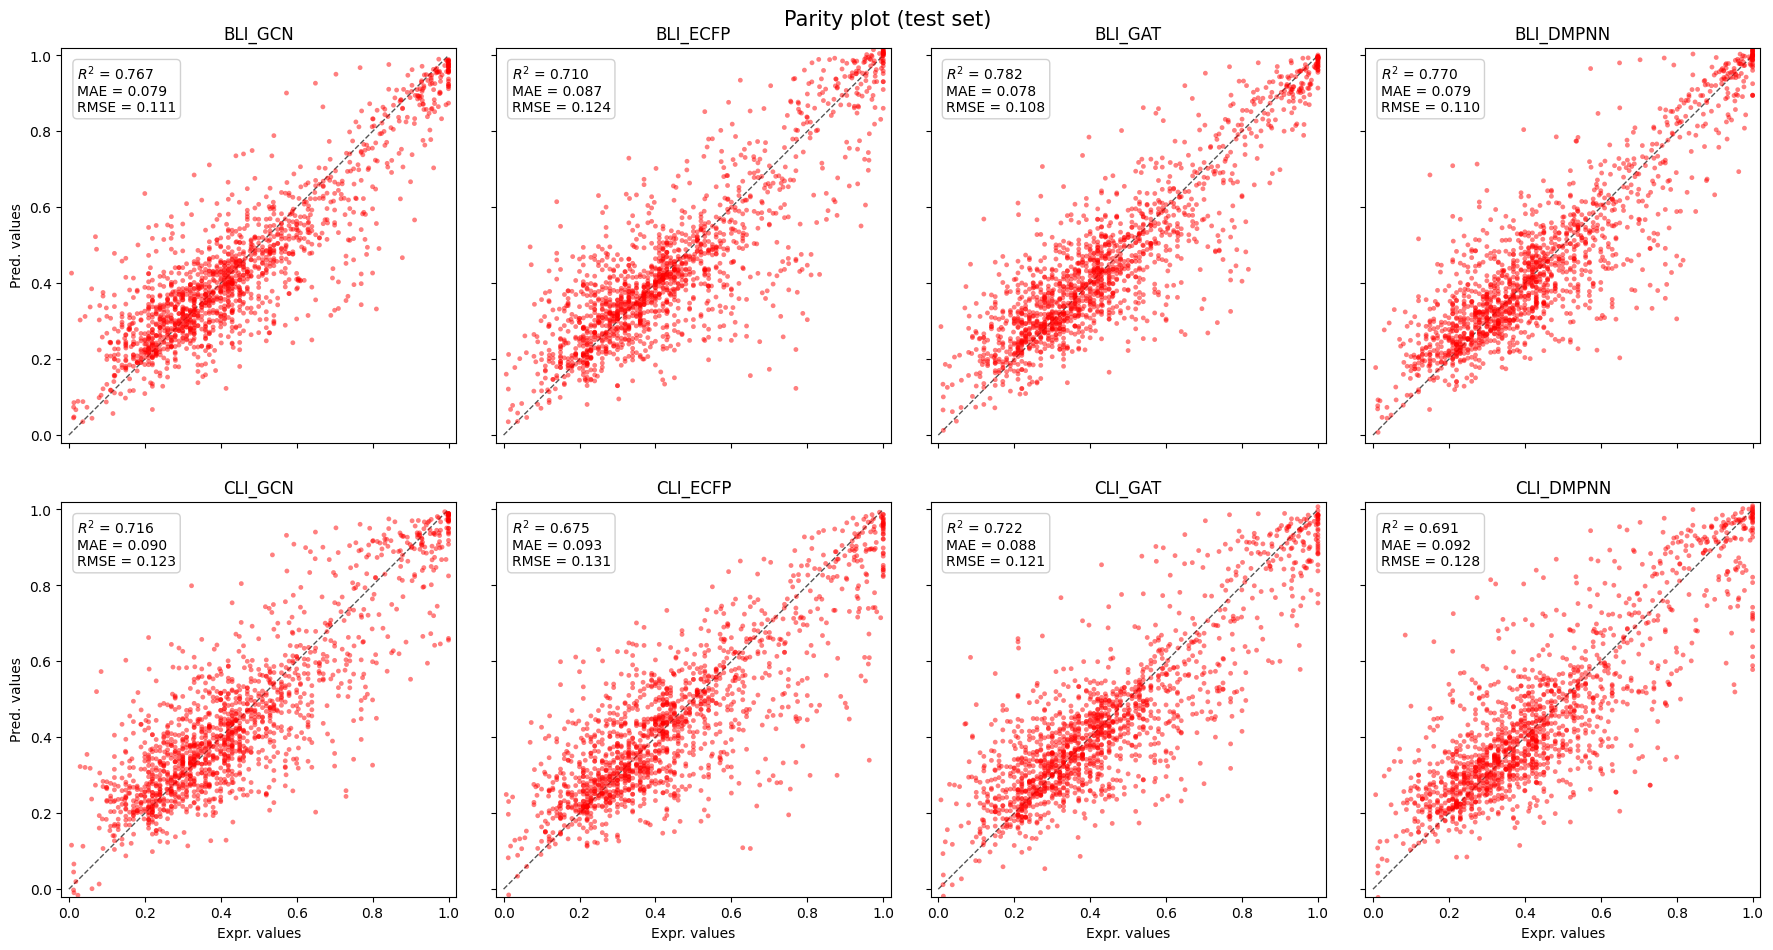

In [30]:
def parity_ax(ax, df, title, style, s=10, alpha=0.5, show_metrics=True):
    ax.scatter(df['label'], df['pred'], s=s, alpha=alpha, edgecolors='none', **style)
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color='#555555', zorder=0)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=12)
    # ax.grid(True, color='#e5e5e5', lw=0.6)
    ax.set_axisbelow(True)
    if show_metrics:
        m = calc_metrics(df)
        ax.text(0.04, 0.96,
                f"$R^2$ = {m['R2']:.3f}\nMAE = {m['MAE']:.3f}\nRMSE = {m['RMSE']:.3f}",
                transform=ax.transAxes, va='top', ha='left', fontsize=10,
                bbox=dict(boxstyle='round', fc='white', ec='#cccccc', alpha=0.9))


def plot_grid(split, s=12, alpha=0.5):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9.5), sharex=True, sharey=True)
    for ax, name in zip(axes.flat, MODELS):
        parity_ax(ax, data[(name, split)], name, SPLIT_STYLE[split], s=s, alpha=alpha)
    for ax in axes[1]:
        ax.set_xlabel('Expr. values')
    for ax in axes[:, 0]:
        ax.set_ylabel('Pred. values')
    fig.suptitle(f'Parity plot ({split} set)', fontsize=15)
    fig.tight_layout()
    fig.subplots_adjust(hspace=0.15)
    fig.savefig(OUT_DIR / f'parity_grid_{split}.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_grid('train', s=4, alpha=0.25)
plot_grid('valid')
plot_grid('test')